# 02 – Approach A1: A Transformer Encoder Trained from Scratch
**DS5007 NLP · Assignment 2 · Extractive QA on SQuAD 1.1**

**Goal.** Build every part of a Transformer encoder ourselves (token embeddings, positional embeddings, multi-head self-attention, feed-forward networks, residual connections, layer normalisation, and start/end prediction heads) and train it on SQuAD 1.1 from **random initialisation**. No pretrained weights are used. Only the tokenizer's vocabulary (a fixed list of 30,522 WordPiece strings) is borrowed so all approaches see identical inputs.

**Why this approach (empirical motivation).** A1 answers the question *"how far can a Transformer get using only the 88k SQuAD questions?"*. It is the baseline against which the value of pretraining (A2/A3) is measured.

**Why this architecture size.** 4 layers, $d_{model}=256$, 4 heads ($d_k = 64$), FFN width 1024 and learned positions up to 512 give about 11M parameters, about 70% of them in the embedding table. The model is large enough to learn question–context matching, yet one epoch over all 88k training windows takes only a couple of minutes on a 6 GB laptop GPU, so up to 10 epochs with early stopping are affordable. We use **pre-LayerNorm** blocks because they train stably from scratch with a relatively large learning rate (5e-4) and warm-up.

## 1. Setup and data
Same data pipeline as notebook 01: SQuAD 1.1, offset-aligned labels, **sliding windows** of 384 tokens with 128 tokens of overlap (A1 sees the same inputs as A3).

In [1]:
# Environment: on Google Colab, mount Drive and work inside the uploaded project folder; locally nothing to do.
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = "/content/drive/MyDrive/EQA_Assignment"      # <- path of the uploaded project folder
    os.chdir(os.path.join(PROJECT_DIR, "notebooks"))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "transformers>=4.40", "datasets", "gradio"])
sys.path.insert(0, os.path.abspath(".."))                     # make eqa_lib.py (project root) importable

import eqa_lib as eqa          # imported first: it initialises OpenSSL before torch/pyarrow (Windows workaround)
import json, time, re, collections, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 120)
ENV = eqa.setup()

python         : 3.14.6
torch          : 2.14.1+cu126
transformers   : 5.19.0
numpy          : 2.4.6
pandas         : 3.0.3
device         : cuda
gpu            : NVIDIA GeForce RTX 4050 Laptop GPU
gpu_memory_gb  : 6.0
cuda           : 12.6
amp_dtype      : torch.bfloat16
seed           : 42
quick_run      : False
force_retrain  : False
project_root   : C:\Users\kiran\NLP Assignment 2\EQA_Assignment


In [2]:
RUN = "transformer_scratch"
RC = dict(arch="scratch",
          scratch=dict(d_model=256, n_heads=4, n_layers=4, d_ff=1024, max_len=512, dropout=0.1),
          input_strategy="sliding_window", max_length=384, doc_stride=128,
          lr=5e-4, batch_size=32, epochs=10, warmup_ratio=0.1, weight_decay=0.01, max_grad_norm=1.0,
          evals_per_epoch=1, patience=2, train_fraction=1.0)
if eqa.QUICK_RUN:
    RC["epochs"] = 2
print(json.dumps(RC, indent=2))

train_raw, val_df, _ = eqa.load_squad()
train_df, _ = eqa.clean_training_data(train_raw)
tokenizer = eqa.get_tokenizer()
t0 = time.time()
train_feats, train_stats = eqa.prepare_features(train_df, tokenizer, RC["max_length"], RC["doc_stride"], sliding_window=True)
val_feats, val_stats = eqa.prepare_features(val_df, tokenizer, RC["max_length"], RC["doc_stride"], sliding_window=True, keep_offsets=True)
print(f"{len(train_df):,} training questions -> {train_stats['features']:,} windows | "
      f"{len(val_df):,} validation questions -> {val_stats['features']:,} windows   ({time.time() - t0:.0f}s)")

{
  "arch": "scratch",
  "scratch": {
    "d_model": 256,
    "n_heads": 4,
    "n_layers": 4,
    "d_ff": 1024,
    "max_len": 512,
    "dropout": 0.1
  },
  "input_strategy": "sliding_window",
  "max_length": 384,
  "doc_stride": 128,
  "lr": 0.0005,
  "batch_size": 32,
  "epochs": 10,
  "warmup_ratio": 0.1,
  "weight_decay": 0.01,
  "max_grad_norm": 1.0,
  "evals_per_epoch": 1,
  "patience": 2,
  "train_fraction": 1.0
}


[info] `datasets` not usable here (ImportError: DLL load failed while importing _xxhash: An Application Control policy has block...)
[info] Falling back to the identical parquet files on the Hugging Face Hub.


Loaded from huggingface_hub: rajpurkar/squad (plain_text parquet): 87,599 training / 10,570 validation examples


87,599 training questions -> 88,524 windows | 10,570 validation questions -> 10,784 windows   (18s)


## 2. The architecture, component by component
```
input_ids, token_type_ids, attention_mask            [CLS] q1 … qm [SEP] c1 … ck [SEP]
   │
   ▼  (1) embeddings:  e_i = E_tok[x_i] + E_pos[i] + E_seg[s_i]  → LayerNorm → dropout          (B, L, 256)
   ▼  (2) 4 × EncoderBlock (pre-LN):
   │        x = x + Dropout( MultiHeadSelfAttention( LayerNorm(x) ) )     ← residual 1
   │        x = x + Dropout( FeedForward( LayerNorm(x) ) )                ← residual 2
   ▼  (3) final LayerNorm  → contextual representations h_1 … h_L                                (B, L, 256)
   ├──────────────► start head  s_i = w_s·h_i + b_s  → softmax → P_start(i | q, c)
   └──────────────► end head    e_j = w_e·h_j + b_e  → softmax → P_end(j | q, c)
```

### 2.1 Token, positional and segment embeddings
Self-attention is permutation-invariant: without position information, "Turing introduced X" and "X introduced Turing" would look identical. We therefore add a **learned positional embedding** $E_{pos}[i]$ (one vector per position 0..511, as in BERT) to the **token embedding** $E_{tok}[x_i]$. A **segment embedding** $E_{seg}[s_i]$ ($s_i = 0$ for question tokens, 1 for context tokens) tells the encoder which part of the packed sequence a token belongs to. The sum is layer-normalised.

In [3]:
eqa.show_source(eqa.ScratchTransformerQA)

```python
class ScratchTransformerQA(nn.Module):
    """Approach A1: Transformer encoder trained from random initialisation + start/end span heads.

    input embedding e_i = E_tok[x_i] + E_pos[i] + E_seg[s_i]  (learned token, position and segment embeddings)
    -> LayerNorm -> dropout -> N x EncoderBlock -> final LayerNorm -> SpanHeads
    """

    def __init__(self, vocab_size, d_model=256, n_heads=4, n_layers=4, d_ff=1024, max_len=512, dropout=0.1, pad_id=0):
        super().__init__()
        self.tok_emb = nn.Embedding(vocab_size, d_model, padding_idx=pad_id)
        self.pos_emb = nn.Embedding(max_len, d_model)
        self.seg_emb = nn.Embedding(2, d_model)
        self.emb_norm, self.emb_dropout = nn.LayerNorm(d_model), nn.Dropout(dropout)
        self.blocks = nn.ModuleList([EncoderBlock(d_model, n_heads, d_ff, dropout) for _ in range(n_layers)])
        self.final_norm = nn.LayerNorm(d_model)
        self.heads = SpanHeads(d_model, dropout)
        self.uses_token_type_ids = True
        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, std=0.02)
        if isinstance(m, nn.Linear) and m.bias is not None:
            nn.init.zeros_(m.bias)

    def encode(self, input_ids, attention_mask, token_type_ids=None):
        positions = torch.arange(input_ids.size(1), device=input_ids.device).unsqueeze(0)
        if token_type_ids is None:
            token_type_ids = torch.zeros_like(input_ids)
        x = self.tok_emb(input_ids) + self.pos_emb(positions) + self.seg_emb(token_type_ids)
        x = self.emb_dropout(self.emb_norm(x))
        for block in self.blocks:
            x = block(x, attention_mask)
        return self.final_norm(x)                                # contextual representations h_1..h_L

    def forward(self, input_ids, attention_mask, token_type_ids=None, start_positions=None, end_positions=None):
        hidden = self.encode(input_ids, attention_mask, token_type_ids)
        return self.heads(hidden, attention_mask, start_positions, end_positions)

```

### 2.2 Multi-head self-attention
For an input $X \in \mathbb{R}^{L\times d}$ each head $h$ projects every token to a query, key and value:
$$Q_h = XW^Q_h,\quad K_h = XW^K_h,\quad V_h = XW^V_h \qquad (W_h \in \mathbb{R}^{d\times d_k},\ d_k = d/H = 64)$$
$$\operatorname{head}_h = \operatorname{softmax}\!\Big(\frac{Q_hK_h^\top}{\sqrt{d_k}} + M\Big)V_h, \qquad \operatorname{MHSA}(X) = [\operatorname{head}_1;\dots;\operatorname{head}_H]\,W^O .$$
* $Q_hK_h^\top$ scores how relevant token $j$ (key) is for token $i$ (query); dividing by $\sqrt{d_k}$ keeps the scores' variance ≈ 1 so the softmax does not saturate.
* $M_{ij} = -\infty$ if token $j$ is padding (attention mask 0), so padding receives exactly zero weight.
* Each row of the softmax is a probability distribution, and the output for token $i$ is the weighted average of the value vectors.
* Several heads learn different relations in parallel (e.g. question word ↔ matching context word, or token ↔ neighbouring tokens).

The implementation computes all heads at once by reshaping $(B, L, d) \to (B, H, L, d_k)$:

In [4]:
eqa.show_source(eqa.MultiHeadSelfAttention)
# Verification 1: our attention equals PyTorch's reference implementation (dropout off)
import torch.nn.functional as F
torch.manual_seed(0)
mha = eqa.MultiHeadSelfAttention(256, 4, dropout=0.0).eval()
x = torch.randn(2, 10, 256); mask = torch.ones(2, 10, dtype=torch.long); mask[1, 7:] = 0   # 2nd sequence: 3 padding tokens
out, w = mha(x, mask, return_weights=True)
split = lambda t: t.view(2, 10, 4, 64).transpose(1, 2)
ref = F.scaled_dot_product_attention(split(mha.q_proj(x)), split(mha.k_proj(x)), split(mha.v_proj(x)),
                                     attn_mask=(mask[:, None, None, :] == 1))
ref = mha.out_proj(ref.transpose(1, 2).reshape(2, 10, 256))
print(f"max |ours - torch.nn.functional.scaled_dot_product_attention| = {(out - ref).abs().max().item():.2e}")
print("attention rows sum to 1:", torch.allclose(w.sum(-1), torch.ones(2, 4, 10)),
      "| largest weight given to padding keys:", w[1, :, :, 7:].max().item())

```python
class MultiHeadSelfAttention(nn.Module):
    """Multi-head scaled dot-product self-attention, written out explicitly.

    For each head h:  Q_h = X W_q^h,  K_h = X W_k^h,  V_h = X W_v^h
                      head_h = softmax( Q_h K_h^T / sqrt(d_k) + M ) V_h      (M = -inf on padding keys)
    Output: concat(head_1..head_H) W_o
    """

    def __init__(self, d_model, n_heads, dropout=0.1):
        super().__init__()
        assert d_model % n_heads == 0, "d_model must be divisible by n_heads"
        self.n_heads, self.d_k = n_heads, d_model // n_heads
        self.q_proj = nn.Linear(d_model, d_model)
        self.k_proj = nn.Linear(d_model, d_model)
        self.v_proj = nn.Linear(d_model, d_model)
        self.out_proj = nn.Linear(d_model, d_model)
        self.attn_dropout = nn.Dropout(dropout)

    def forward(self, x, attention_mask, return_weights=False):
        B, L, D = x.shape

        def split_heads(t):                                   # (B, L, D) -> (B, H, L, d_k)
            return t.view(B, L, self.n_heads, self.d_k).transpose(1, 2)

        q, k, v = split_heads(self.q_proj(x)), split_heads(self.k_proj(x)), split_heads(self.v_proj(x))
        scores = q @ k.transpose(-2, -1) / math.sqrt(self.d_k)              # (B, H, L, L) similarity of every pair
        key_is_pad = (attention_mask == 0)[:, None, None, :]                 # broadcast over heads and queries
        scores = scores.float().masked_fill(key_is_pad, float("-inf"))
        weights = scores.softmax(dim=-1).to(v.dtype)                         # each row sums to 1
        context = self.attn_dropout(weights) @ v                            # (B, H, L, d_k) weighted sum of values
        context = context.transpose(1, 2).reshape(B, L, D)                  # concatenate the heads
        out = self.out_proj(context)
        return (out, weights) if return_weights else out

```

max |ours - torch.nn.functional.scaled_dot_product_attention| = 1.79e-07
attention rows sum to 1: True | largest weight given to padding keys: 0.0


### 2.3 Feed-forward network, residual connections and layer normalisation
* **FFN:** $\operatorname{FFN}(x) = W_2\,\operatorname{GELU}(W_1x + b_1) + b_2$ with $W_1 \in \mathbb{R}^{256\times1024}$. It is applied to every position independently and adds non-linear transformation capacity after attention has mixed the information.
* **Residual connections:** $x \leftarrow x + \operatorname{Sublayer}(\operatorname{LN}(x))$. Gradients flow directly through the identity path, so deeper stacks remain trainable, and each layer only learns a *correction* to its input.
* **Layer normalisation:** $\operatorname{LN}(x) = \gamma \odot \frac{x - \mu}{\sqrt{\sigma^2 + \epsilon}} + \beta$ over the feature dimension of each token. This keeps activations in a stable range. *Pre*-LN (normalise before each sub-layer, plus one final LN) avoids the warm-up sensitivity of the original post-LN Transformer when training from scratch.

In [5]:
eqa.show_source(eqa.FeedForward, eqa.EncoderBlock)

```python
class FeedForward(nn.Module):
    """Position-wise feed-forward network: Linear(d -> d_ff) -> GELU -> dropout -> Linear(d_ff -> d)."""

    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()
        self.fc1, self.fc2 = nn.Linear(d_model, d_ff), nn.Linear(d_ff, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.fc2(self.dropout(F.gelu(self.fc1(x))))

```

```python
class EncoderBlock(nn.Module):
    """Pre-LayerNorm Transformer encoder block with two residual connections:
         x = x + Dropout(MHSA(LN(x)))
         x = x + Dropout(FFN(LN(x)))
    """

    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.ln_attn, self.ln_ffn = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.attn = MultiHeadSelfAttention(d_model, n_heads, dropout)
        self.ffn = FeedForward(d_model, d_ff, dropout)
        self.drop_attn, self.drop_ffn = nn.Dropout(dropout), nn.Dropout(dropout)

    def forward(self, x, attention_mask):
        x = x + self.drop_attn(self.attn(self.ln_attn(x), attention_mask))   # residual connection 1
        x = x + self.drop_ffn(self.ffn(self.ln_ffn(x)))                       # residual connection 2
        return x

```

### 2.4 How the encoder processes a question–context pair
The question and the context are **one** sequence. In every layer each context token attends to every question token and vice versa, so after a few layers a context token's vector $h_i$ encodes whether it matches the question ("which **year** … **introduce** …") as well as its local context ("… machine **in 1936** ."). No separate cross-attention module is needed. The segment embedding tells the model which side of `[SEP]` a token is on.

### 2.5 The two prediction heads and the loss
Two independent linear layers map every contextual vector to a scalar score: $s_i = w_s^\top h_i + b_s$ (start) and $e_j = w_e^\top h_j + b_e$ (end). A softmax over positions turns them into $P_{\text{start}}(i\mid q,c)$ and $P_{\text{end}}(j\mid q,c)$, with padding masked. Training minimises
$$\mathcal{L} = -\tfrac{1}{2}\big[\log P_{\text{start}}(y_s) + \log P_{\text{end}}(y_e)\big],$$
where windows without the answer use $y_s = y_e = 0$ (`[CLS]`). At inference, `eqa.postprocess_predictions` (notebook 01) searches the best valid span $\arg\max_{i\le j,\ j-i<30} s_i + e_j$ over all windows and slices the answer out of the original context with the character offsets.

These heads, the loss and the span search are **shared by all three approaches**.

In [6]:
eqa.show_source(eqa.SpanHeads, eqa.qa_loss)
model = eqa.build_model(RC).to(eqa.DEVICE)
groups = {"token embeddings": model.tok_emb, "position embeddings": model.pos_emb, "segment embeddings": model.seg_emb,
          "embedding LayerNorm": model.emb_norm, "4 encoder blocks": model.blocks, "final LayerNorm": model.final_norm,
          "start + end heads": model.heads}
param_tbl = pd.DataFrame({"parameters": {k: eqa.count_parameters(m) for k, m in groups.items()}})
param_tbl["share (%)"] = (100 * param_tbl["parameters"] / param_tbl["parameters"].sum()).round(2)
param_tbl.loc["TOTAL"] = [param_tbl["parameters"].sum(), 100.0]
display(param_tbl)

# Verification 2: forward pass on a real batch – shapes, valid distributions, initial loss ≈ ln(L)
batch = eqa.collate([eqa.QAFeatureDataset(train_feats)[i] for i in range(8)])
batch.pop("feature_idx")
batch = {k: v.to(eqa.DEVICE) for k, v in batch.items()}
model.eval()
with torch.no_grad(), eqa.autocast_ctx():
    out = model(**batch)
L = batch["input_ids"].shape[1]
print(f"input_ids {tuple(batch['input_ids'].shape)} -> start_logits {tuple(out['start_logits'].shape)}, end_logits {tuple(out['end_logits'].shape)}")
print("P_start sums to 1 per sequence:", torch.allclose(out["start_logits"].softmax(-1).sum(-1), torch.ones(8, device=eqa.DEVICE)))
print(f"loss of the untrained model = {out['loss'].item():.3f}  (uniform guess over the real tokens ≈ ln(mean length) = "
      f"{np.log(batch['attention_mask'].sum(1).float().mean().item()):.3f})")
del model

```python
class SpanHeads(nn.Module):
    """Start-position head and end-position head: two independent linear maps R^d -> R (one score per token).

    s_i = w_s . h_i + b_s,   e_j = w_e . h_j + b_e;  padding positions get -1e4 so softmax gives them ~0 probability.
    """

    def __init__(self, hidden_size, dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        self.start_head = nn.Linear(hidden_size, 1)
        self.end_head = nn.Linear(hidden_size, 1)
        for lin in (self.start_head, self.end_head):
            nn.init.normal_(lin.weight, std=0.02)
            nn.init.zeros_(lin.bias)

    def forward(self, hidden, attention_mask, start_positions=None, end_positions=None):
        hidden = self.dropout(hidden)
        start_logits = self.start_head(hidden).squeeze(-1).float()      # (B, L)
        end_logits = self.end_head(hidden).squeeze(-1).float()          # (B, L)
        pad = attention_mask == 0
        start_logits = start_logits.masked_fill(pad, -1e4)
        end_logits = end_logits.masked_fill(pad, -1e4)
        out = {"start_logits": start_logits, "end_logits": end_logits}
        if start_positions is not None and end_positions is not None:
            out["loss"] = qa_loss(start_logits, end_logits, start_positions, end_positions)
        return out

```

```python
def qa_loss(start_logits, end_logits, start_positions, end_positions, reduction="mean"):
    """L = ( CE(P_start, y_start) + CE(P_end, y_end) ) / 2."""
    return (F.cross_entropy(start_logits, start_positions, reduction=reduction)
            + F.cross_entropy(end_logits, end_positions, reduction=reduction)) / 2

```

,parameters,share (%)
token embeddings,7813632.0,70.36
position embeddings,131072.0,1.18
segment embeddings,512.0,0.00
embedding LayerNorm,512.0,0.00
4 encoder blocks,3159040.0,28.44
final LayerNorm,512.0,0.00
start + end heads,514.0,0.00
TOTAL,11105794.0,100.00


input_ids (8, 271) -> start_logits (8, 271), end_logits (8, 271)
P_start sums to 1 per sequence: True
loss of the untrained model = 5.348  (uniform guess over the real tokens ≈ ln(mean length) = 5.346)


## 3. Training
`eqa.train_model` is the training loop shared by all approaches:
* **DataLoader** with dynamic padding and length-grouped batches (notebook 01 §4.4).
* **AdamW** (decoupled weight decay 0.01, none on biases/LayerNorm) with a **10% linear warm-up then linear decay** of the learning rate.
* **Gradient clipping** at global norm 1.0. **Mixed precision** (bf16 on this GPU, fp16 + loss scaling on a Colab T4).
* After every epoch: **validation loss, EM and F1 on all 10,570 validation questions**. The **best-F1 checkpoint** is saved to `models/transformer_scratch/`, and training **stops early** after 2 evaluations without improvement.
* Wall-clock time (with and without validation passes), peak GPU memory and the full log are recorded. If the run already exists it is reloaded and its log replayed instead of retraining (`EQA_FORCE_RETRAIN=1` overrides this).

Hyper-parameters for training from scratch: learning rate 5e-4 (10× the fine-tuning rate, since there is no pretrained knowledge to preserve), batch 32, at most 10 epochs.

In [7]:
eqa.show_source(eqa.train_model)

```python
def train_model(run_name, rc, train_feats, val_feats, val_df, save_ckpt=True, model_dir=None):
    """Train one configuration with AdamW + warm-up/linear decay + clipping + mixed precision, evaluating EM/F1 on
    the validation set `evals_per_epoch` times per epoch, keeping the best-F1 checkpoint and stopping early after
    `patience` evaluations without improvement. Cached: if the run exists it is reloaded instead of retrained.
    Returns (best model or None, history dict)."""
    from torch.utils.data import DataLoader
    run_dir = Path(model_dir) if model_dir else PATHS.models / run_name
    hist_path = PATHS.logs / f"history_{run_name}.json"
    if not FORCE_RETRAIN and hist_path.exists() and (not save_ckpt or (run_dir / "best_model.pt").exists()):
        history = json.loads(hist_path.read_text())
        print(f"[cache] '{run_name}' already trained – replaying its saved log (set EQA_FORCE_RETRAIN=1 to retrain).")
        for line in history["log_lines"]:
            print(line)
        return (load_qa_model(run_dir) if save_ckpt else None), history

    set_seed(SEED)
    model = build_model(rc).to(DEVICE)
    n_examples = max(train_feats["example_idx"]) + 1
    if rc.get("train_fraction", 1.0) < 1.0:     # reproducible subset of QUESTIONS (all windows of a question kept)
        rng = np.random.default_rng(SEED)
        keep = set(rng.permutation(n_examples)[: int(round(rc["train_fraction"] * n_examples))].tolist())
        feat_idx = [f for f, ex in enumerate(train_feats["example_idx"]) if ex in keep]
        n_used = len(keep)
    else:
        feat_idx, n_used = list(range(len(train_feats["input_ids"]))), n_examples
    sampler = LengthGroupedBatchSampler([len(train_feats["input_ids"][f]) for f in feat_idx], rc["batch_size"])
    loader = DataLoader(QAFeatureDataset(train_feats, indices=feat_idx), batch_sampler=sampler, collate_fn=collate,
                        pin_memory=DEVICE.type == "cuda")

    decay = [p for p in model.parameters() if p.ndim >= 2]
    no_decay = [p for p in model.parameters() if p.ndim < 2]          # biases and LayerNorm weights
    optimizer = torch.optim.AdamW([{"params": decay, "weight_decay": rc["weight_decay"]},
                                   {"params": no_decay, "weight_decay": 0.0}], lr=rc["lr"], betas=(0.9, 0.999), eps=1e-8)
    steps_per_epoch = len(sampler)
    total_steps = steps_per_epoch * rc["epochs"]
    warmup_steps = int(rc["warmup_ratio"] * total_steps)

    def lr_lambda(step):           # linear warm-up, then linear decay to 0
        if step < warmup_steps:
            return step / max(1, warmup_steps)
        return max(0.0, (total_steps - step) / max(1, total_steps - warmup_steps))

    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
    scaler = torch.amp.GradScaler("cuda", enabled=(AMP_DTYPE == torch.float16))
    evals_per_epoch = rc.get("evals_per_epoch", 1)
    eval_points = {round(steps_per_epoch * k / evals_per_epoch) for k in range(1, evals_per_epoch + 1)}
    log_every = max(20, steps_per_epoch // 10)

    lines = []
    history = {"run_name": run_name, "config": rc, "train_log": [], "evals": [], "log_lines": lines,
               "n_params": count_parameters(model), "n_train_examples": n_used, "n_train_features": len(feat_idx),
               "steps_per_epoch": steps_per_epoch, "n_val_features": len(val_feats["input_ids"])}
    _log(f"=== {run_name}: {history['n_params'] / 1e6:.2f}M params | {n_used:,} questions -> {len(feat_idx):,} inputs | "
         f"{rc['epochs']} epochs x {steps_per_epoch} steps (batch {rc['batch_size']}, lr {rc['lr']}) ===", lines)
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    best_f1, bad_evals, global_step, stop, eval_time = -1.0, 0, 0, False, 0.0
    t_start = time.time()
    for epoch in range(rc["epochs"]):
        model.train()
        sampler.set_epoch(epoch)
        win_loss = win_n = period_loss = period_n = 0
        for step_in_epoch, batch in enumerate(loader, start=1):
            batch.pop("feature_idx")
            batch = {k: v.to(DEVICE, non_blocking=True) for k, v in batch.items()}
            with autocast_ctx():
                loss = model(**batch)["loss"]
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), rc["max_grad_norm"])
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            scheduler.step()
            global_step += 1
            lv = loss.item()
            win_loss += lv; win_n += 1; period_loss += lv; period_n += 1

            if global_step % log_every == 0:
                elapsed = time.time() - t_start
                eta = (elapsed - eval_time) / global_step * (total_steps - global_step)
                rec = {"step": global_step, "epoch": global_step / steps_per_epoch, "loss": win_loss / win_n,
                       "lr": scheduler.get_last_lr()[0]}
                history["train_log"].append(rec)
                _log(f"[{run_name}] epoch {epoch + 1}/{rc['epochs']} step {step_in_epoch:>5}/{steps_per_epoch} | "
                     f"train loss {rec['loss']:.4f} | lr {rec['lr']:.2e} | {elapsed / 60:5.1f} min, ETA {eta / 60:5.1f} min", lines)
                win_loss = win_n = 0

            if step_in_epoch in eval_points:
                ev = evaluate_model(model, val_feats, val_df)
                eval_time += ev["eval_seconds"]
                rec = {"step": global_step, "epoch": global_step / steps_per_epoch, "train_loss": period_loss / period_n,
                       "val_loss": ev["val_loss"], "exact_match": ev["exact_match"], "f1": ev["f1"],
                       "elapsed_min": (time.time() - t_start) / 60, "eval_seconds": ev["eval_seconds"],
                       "forward_seconds": ev["forward_seconds"]}
                history["evals"].append(rec)
                improved = ev["f1"] > best_f1
                _log(f"[{run_name}] >>> eval @ epoch {rec['epoch']:.2f}: train loss {rec['train_loss']:.4f} | "
                     f"val loss {rec['val_loss']:.4f} | EM {rec['exact_match']:.2f} | F1 {rec['f1']:.2f}"
                     f"{'  (new best)' if improved else ''}", lines)
                period_loss = period_n = 0
                if improved:
                    best_f1, bad_evals, history["best"] = ev["f1"], 0, rec
                    if save_ckpt:
                        save_checkpoint(model, run_dir, rc, rec)
                else:
                    bad_evals += 1
                    if bad_evals >= rc["patience"]:
                        _log(f"[{run_name}] early stopping: no F1 improvement for {bad_evals} evaluations", lines)
                        stop = True
                        break
                model.train()
        if stop:
            break

    total_min = (time.time() - t_start) / 60
    history.update({
        "train_time_min": total_min,                               # wall clock incl. validation passes
        "pure_train_time_min": total_min - eval_time / 60,        # optimisation steps only
        "epochs_run": global_step / steps_per_epoch,
        "peak_gpu_mem_gb": torch.cuda.max_memory_allocated() / 1024 ** 3 if DEVICE.type == "cuda" else None,
        "model_size_mb": (run_dir / "best_model.pt").stat().st_size / 1e6 if save_ckpt else
                         sum(t.numel() * t.element_size() for t in model.state_dict().values()) / 1e6,
    })
    _log(f"[{run_name}] done: {total_min:.1f} min ({history['pure_train_time_min']:.1f} min training, "
         f"{eval_time / 60:.1f} min validation) | best F1 {best_f1:.2f} | peak GPU memory {history['peak_gpu_mem_gb'] or 0:.2f} GB", lines)
    save_json(history, hist_path)
    del optimizer, scheduler, loader
    model = load_qa_model(run_dir) if save_ckpt else None
    import gc
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return model, history

```

In [8]:
model, hist = eqa.train_model(RUN, RC, train_feats, val_feats, val_df)

=== transformer_scratch: 11.11M params | 87,599 questions -> 88,524 inputs | 10 epochs x 2767 steps (batch 32, lr 0.0005) ===


[transformer_scratch] epoch 1/10 step   276/2767 | train loss 4.8958 | lr 4.99e-05 |   0.2 min, ETA  17.4 min


[transformer_scratch] epoch 1/10 step   552/2767 | train loss 4.4835 | lr 9.97e-05 |   0.3 min, ETA  16.5 min


[transformer_scratch] epoch 1/10 step   828/2767 | train loss 4.4001 | lr 1.50e-04 |   0.6 min, ETA  18.8 min


[transformer_scratch] epoch 1/10 step  1104/2767 | train loss 4.2752 | lr 1.99e-04 |   0.8 min, ETA  19.2 min


[transformer_scratch] epoch 1/10 step  1380/2767 | train loss 4.2634 | lr 2.49e-04 |   1.0 min, ETA  19.4 min


... (70 outputs left out)

[transformer_scratch] epoch 7/10 step  2718/2767 | train loss 2.7339 | lr 1.68e-04 |  13.2 min, ETA   5.3 min


[transformer_scratch] >>> eval @ epoch 7.00: train loss 2.6953 | val loss 4.4883 | EM 10.01 | F1 18.64


[transformer_scratch] early stopping: no F1 improvement for 2 evaluations


[transformer_scratch] done: 13.4 min (12.3 min training, 1.1 min validation) | best F1 20.09 | peak GPU memory 1.32 GB


## 4. Results
### 4.1 Training and validation curves

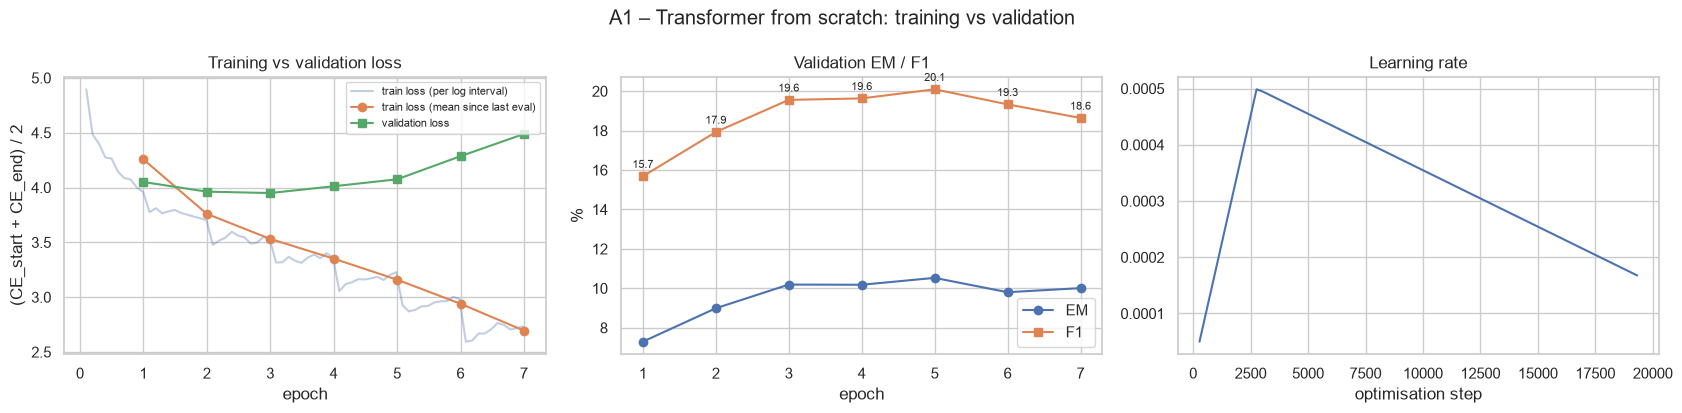

,epoch,train_loss,val_loss,exact_match,f1,elapsed_min
0,1.0,4.257,4.050,7.294,15.684,2.013
1,2.0,3.760,3.962,8.988,17.927,3.783
2,3.0,3.532,3.950,10.189,19.557,5.560
3,4.0,3.352,4.012,10.180,19.632,7.410
4,5.0,3.160,4.075,10.530,20.094,9.254
5,6.0,2.940,4.286,9.801,19.329,11.329
6,7.0,2.695,4.488,10.009,18.639,13.396


In [9]:
eqa.plot_history(hist, "A1 – Transformer from scratch: training vs validation")
eqa.savefig("02_A1_training_curves")
display(pd.DataFrame(hist["evals"])[["epoch", "train_loss", "val_loss", "exact_match", "f1", "elapsed_min"]].round(3))

In [10]:
ev = eqa.evaluate_model(model, val_feats, val_df)
print(f"A1 best checkpoint (epoch {hist['best']['epoch']:.0f}) on the full validation set ({len(val_df):,} questions):")
print(f"   Exact Match = {ev['exact_match']:.2f}   F1 = {ev['f1']:.2f}   validation loss = {ev['val_loss']:.4f}")
print(f"   training time {hist['train_time_min']:.1f} min ({hist['pure_train_time_min']:.1f} min excluding validation), "
      f"{hist['epochs_run']:.0f} epochs, peak GPU memory {hist['peak_gpu_mem_gb']:.2f} GB")
print(f"   inference: {ev['forward_seconds']:.1f} s for {ev['n_features']:,} windows ({ev['features_per_sec']:.0f} windows/s) | "
      f"checkpoint size {hist['model_size_mb']:.1f} MB | {hist['n_params'] / 1e6:.2f}M parameters")
row = eqa.experiment_row(RUN, "A1 Transformer from scratch", hist, ev, "sliding_window", RC["max_length"], RC["doc_stride"])
eqa.log_experiment(row)
eqa.save_json(ev["predictions"], eqa.PATHS.results / f"predictions_{RUN}.json")
ev["details"].to_csv(eqa.PATHS.results / f"details_{RUN}.csv", index=False)
pd.Series(row).to_frame("value")

A1 best checkpoint (epoch 5) on the full validation set (10,570 questions):
   Exact Match = 10.53   F1 = 20.09   validation loss = 4.0750
   training time 13.4 min (12.3 min excluding validation), 7 epochs, peak GPU memory 1.32 GB
   inference: 4.8 s for 10,784 windows (2233 windows/s) | checkpoint size 44.5 MB | 11.11M parameters


,value
run,transformer_scratch
approach,A1 Transformer from scratch
input_strategy,sliding_window
max_length,384
doc_stride,128
train_fraction,1.0
train_questions,87599
train_inputs,88524
params_M,11.105794
model_size_MB,44.450293


### 4.2 What does the model predict?

In [11]:
d = ev["details"].merge(val_df[["id", "question", "answer_texts"]], on="id")
d["outcome"] = np.where(d["em"] == 1, "exact", np.where(d["f1"] > 0, "partial", "wrong"))
print(d["outcome"].value_counts(normalize=True).mul(100).round(1).to_string(), "\n")
for outcome in ("exact", "partial", "wrong"):
    print(f"--- {outcome.upper()} ---")
    for r in d[d["outcome"] == outcome].sample(min(4, (d["outcome"] == outcome).sum()), random_state=eqa.SEED).itertuples():
        print(f"Q: {r.question}\n   gold: {list(dict.fromkeys(r.answer_texts))} | predicted: {r.prediction!r} "
              f"(F1={r.f1:.2f}, confidence={r.confidence:.2f})")
    print()
qtype = val_df.set_index("id").loc[d["id"], "question"].map(eqa.question_type).values
by_q = d.assign(qtype=qtype).groupby("qtype")[["em", "f1"]].mean().mul(100).round(1)
by_q["n"] = d.assign(qtype=qtype)["qtype"].value_counts()
by_q.sort_values("n", ascending=False)

outcome
wrong      61.1
partial    28.4
exact      10.5 

--- EXACT ---
Q: What area was Kublai trying to capture by attacking Xiangyang?
   gold: ['Yangzi River basin', 'the Song dynasty'] | predicted: 'Yangzi River basin' (F1=1.00, confidence=0.01)
Q: How many of the following three fourth quarter drives after the field goal makng the score 16-10 ended in punts?
   gold: ['three', 'The next three drives'] | predicted: 'three' (F1=1.00, confidence=0.06)
Q: What did European chemists make that could be used in warfare?
   gold: ['deadly explosives', 'explosives'] | predicted: 'deadly explosives' (F1=1.00, confidence=0.01)
Q: What is one country that has been suggested for importation of medicines?
   gold: ['Canada'] | predicted: 'Canada' (F1=1.00, confidence=0.35)

--- PARTIAL ---
Q: What do isolated, spaced out graves of plague victims indicate?
   gold: ['at least some pre-planning and Christian burials', 'some pre-planning and Christian burials'] | predicted: 'Middle East, includin

,em,f1,n
qtype,,,
what,6.4,15.4,6021
who,9.4,22.0,1185
when,35.1,45.1,713
which,8.9,17.1,698
how many,30.8,36.5,642
where,5.9,13.7,476
how,6.5,18.5,432
why,3.9,33.0,155
how much,26.0,38.5,154


### 4.3 What did the attention learn?
Attention weights of the last encoder layer (mean over the 4 heads) for the example from the brief. Each row shows how much a token attends to every other token.

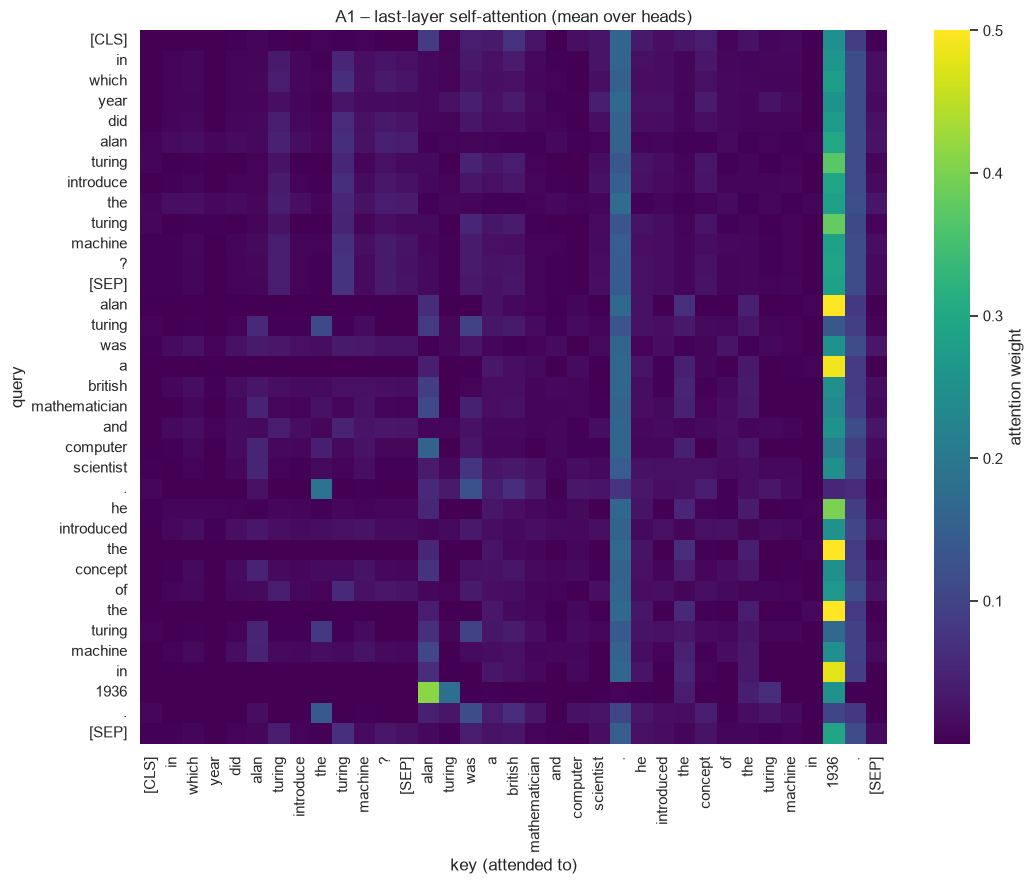

In [12]:
@torch.no_grad()
def attention_maps(model, question, context):
    enc = tokenizer(question, context, return_tensors="pt")
    ids, tt = enc["input_ids"].to(eqa.DEVICE), enc["token_type_ids"].to(eqa.DEVICE)
    am = torch.ones_like(ids)
    model.eval()
    x = model.tok_emb(ids) + model.pos_emb(torch.arange(ids.size(1), device=eqa.DEVICE)[None]) + model.seg_emb(tt)
    x = model.emb_norm(x)
    maps = []
    for blk in model.blocks:
        a, w = blk.attn(blk.ln_attn(x), am, return_weights=True)
        maps.append(w[0].float().mean(0).cpu().numpy())
        x = x + a
        x = x + blk.ffn(blk.ln_ffn(x))
    return tokenizer.convert_ids_to_tokens(ids[0]), maps

demo_q = "In which year did Alan Turing introduce the Turing machine?"
demo_c = "Alan Turing was a British mathematician and computer scientist. He introduced the concept of the Turing machine in 1936."
toks, maps = attention_maps(model, demo_q, demo_c)
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(maps[-1], xticklabels=toks, yticklabels=toks, cmap="viridis", ax=ax, cbar_kws={"label": "attention weight"})
ax.set_title("A1 – last-layer self-attention (mean over heads)"); ax.set_xlabel("key (attended to)"); ax.set_ylabel("query")
eqa.savefig("02_A1_attention_map")

## 5. Discussion: strengths and limitations of training from scratch
**Results (measured above).** The best checkpoint (epoch 5) reaches **EM 10.53 / F1 20.09** on the 10,570 validation questions. Training stopped early after epoch 7, used 13.4 min (12.3 min of optimisation, 1.75 min per epoch) and 1.32 GB of GPU memory. The checkpoint is 44.5 MB (11.1M parameters), and inference over the full validation set takes 4.8 s (≈2,230 windows/s). 61% of the predictions have no overlap with any reference, 28% overlap partially, and 10.5% are exact.

**What the model learned.**
* **Answer-type heuristics, not reading comprehension.** Accuracy is far higher for questions whose answer *type* is easy to spot: *when* (EM 35.1) and *how many* (30.8). For *what* (6.4), *where* (5.9) and *which* (8.9) the answer must be found by matching meaning, and accuracy is much lower. The attention map confirms this: in the last layer almost every token attends to the only number in the paragraph ("1936") and to the sentence boundary. The model has learned "look for a token of the right type", not "find the phrase that answers this question".
* **Rough region, poor boundaries.** Many partial answers start in the right region but run on (e.g. *"Bart Starr (MVP of Super Bowls I and II) and Chuck Howley"* for gold *"Bart Starr"*), because the start and end scores are not sharp.

**Overfitting.** Training loss falls steadily (4.26 → 2.70), but validation loss is lowest at epoch 3 (3.95) and then rises (4.49 at epoch 7), while F1 plateaus around 19–20. With randomly initialised embeddings, the 30,522 WordPiece vectors and the attention weights are fitted to the 88k training questions and do not generalise. Early stopping keeps the epoch-5 weights.

**Limitations of training from scratch on a small dataset.**
1. *No prior language knowledge.* Synonyms, paraphrases, syntax and world knowledge must all be learned from ≈88k questions, while BERT-style models learn them from billions of words. Many WordPiece embeddings are seen only a few times.
2. *Data hunger of Transformers.* Transformers have few built-in inductive biases, so they need much more data than they get here. For comparison, the original SQuAD logistic-regression baseline with hand-crafted lexical and syntactic features reached ≈51 F1 (Rajpurkar et al., 2016). Our 11M-parameter Transformer without features or pretraining stays at ≈20 F1.
3. *Capacity vs. overfitting.* A larger encoder would overfit even faster. A smaller one would underfit question–context matching. Neither fixes the lack of linguistic knowledge.

**Strengths.** A1 is cheap: 8× fewer parameters than DistilBERT, ≈1.3 GB of training memory, 44 MB on disk and very fast inference. Every component is transparent and implemented by us. It is also the reference point that shows how much **pretraining** contributes, which is the motivation for Approaches A2 and A3.